# Aula 2 (assíncrona) — Parte A: notebook guiado

**Grandes Modelos de Linguagem · Residência em Engenharia de Software Inteligente (FACOM/UFMS)**
Prof. Bruno Nogueira · prazo: até 18/11/2026, 23h59 · atividade **individual** · cerca de 1h30

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bmnogueira-ufms/LLM-ESIA-2026/blob/main/aula02/aula02_notebook_guiado.ipynb)

Neste notebook você vai colocar a mão na massa com os conceitos da Aula 1:

| Exercício | Família / conceito | O que você vai fazer |
|---|---|---|
| 1 | Tokenização | comparar três tokenizadores em textos do **seu MVP** |
| 2 | Encoder-only | gerar embeddings com o BERTimbau, medir similaridade e treinar um classificador |
| 3 | Encoder-decoder | resumir um texto com um T5 em português |
| 4 | Decoder-only | fazer sua primeira chamada a um LLM e resolver **a mesma classificação** do exercício 2 em *zero-shot* |

As células marcadas com **✍️** pedem uma resposta curta sua. Elas vão alimentar a **ficha do caso de uso** (Parte B, em grupo).

> **Antes de começar:** *Ambiente de execução → Alterar o tipo de ambiente de execução → GPU T4*.

## 0. Preparação

In [1]:
!pip install -q tiktoken openai

In [2]:
import time, re, unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import tiktoken
from transformers import AutoTokenizer, AutoModel

device = "cuda" if torch.cuda.is_available() else "cpu"
print("dispositivo:", device)

dispositivo: cuda


### Seus textos

Substitua os exemplos abaixo por **5 a 10 textos reais (ou realistas) do domínio do seu MVP** — mensagens de usuários, descrições, documentos curtos. **Não use dados pessoais ou sensíveis.**

In [3]:
TEXTOS_DO_MVP = [
    'Meu marido disse que vai me matar e que sabe onde meus filhos estudam',
    'Meu ex fica me xingando em mensagens e falando mal de mim para os colegas de trabalho',
    'Ele tentou me enforcar e eu fugi pra casa da vizinha; BO 0000/2025 na DEAM de Campo Grande/MS',
    'Quero renovar a MPU do proc. 0000000-00.2024.8.12.0001 (Lei 11.340/06, art. 22, III)',
    'meu mardio ta me batendo e disse q vai pegar a arma dele',
    'Fui espancada, estou com o rosto machucado e tive que ir ao hospital; ele é policial e anda armado',
    'Posso pedir a medida em nome de uma amiga que sofre violência?',
    'Meu ex ficou com o meu carro e meus documentos e não quer devolver',
]

---
## Exercício 1 — Tokenização

Compare três tokenizadores de famílias diferentes:
- **BERTimbau** (`neuralmind/bert-base-portuguese-cased`) — encoder-only, WordPiece, treinado em português;
- **GPT-4o** (`o200k_base`, via `tiktoken`) — decoder-only proprietário, BPE em bytes;
- **Qwen 2.5** (`Qwen/Qwen2.5-1.5B-Instruct`) — decoder-only aberto, BPE em bytes.

In [4]:
tok_bert = AutoTokenizer.from_pretrained("neuralmind/bert-base-portuguese-cased")
tok_qwen = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-1.5B-Instruct")
enc_gpt4o = tiktoken.get_encoding("o200k_base")

def contar(texto):
    return {
        "BERTimbau": len(tok_bert(texto, add_special_tokens=False)["input_ids"]),
        "GPT-4o":    len(enc_gpt4o.encode(texto)),
        "Qwen2.5":   len(tok_qwen(texto, add_special_tokens=False)["input_ids"]),
    }

linhas = []
for t in TEXTOS_DO_MVP:
    c = contar(t)
    c["palavras"] = len(t.split())
    c["texto"] = t[:60] + ("…" if len(t) > 60 else "")
    linhas.append(c)
df_tok = pd.DataFrame(linhas)
df_tok

tokenizer_config.json:   0%|          | 0.00/43.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/210k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

,BERTimbau,GPT-4o,Qwen2.5,palavras,texto
0,15,15,20,14,Meu marido disse que vai me matar e que sabe o...
1,19,19,23,17,Meu ex fica me xingando em mensagens e falando...
2,29,30,36,18,Ele tentou me enforcar e eu fugi pra casa da v...
3,40,40,57,12,Quero renovar a MPU do proc. 0000000-00.2024.8...
4,14,17,18,13,meu mardio ta me batendo e disse q vai pegar a...
5,26,26,31,19,"Fui espancada, estou com o rosto machucado e t..."
6,14,14,18,12,Posso pedir a medida em nome de uma amiga que ...
7,15,14,18,14,Meu ex ficou com o meu carro e meus documentos...


{'BERTimbau': np.float64(1.48), 'GPT-4o': np.float64(1.5), 'Qwen2.5': np.float64(1.92)}


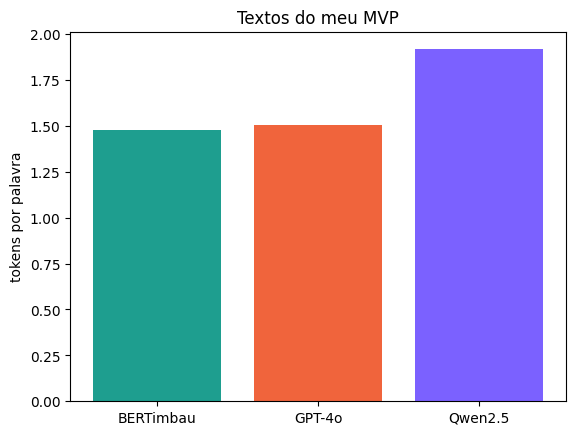

In [5]:
# Tokens por palavra, em média, para cada tokenizador
media = {nome: (df_tok[nome] / df_tok["palavras"]).mean() for nome in ["BERTimbau", "GPT-4o", "Qwen2.5"]}
print({k: round(v, 2) for k, v in media.items()})

plt.bar(media.keys(), media.values(), color=["#1E9E8F", "#F0643C", "#7B61FF"])
plt.ylabel("tokens por palavra")
plt.title("Textos do meu MVP")
plt.show()

In [6]:
# TODO: escolha o texto mais "difícil" da sua lista (siglas, nomes próprios, gírias, códigos)
# e veja como cada tokenizador o quebra.
texto = TEXTOS_DO_MVP[0]
print("BERTimbau:", tok_bert.tokenize(texto))
print("GPT-4o:   ", [enc_gpt4o.decode([i]) for i in enc_gpt4o.encode(texto)])
print("Qwen2.5:  ", [tok_qwen.decode([i]) for i in tok_qwen(texto, add_special_tokens=False)["input_ids"]])

BERTimbau: ['Meu', 'marido', 'disse', 'que', 'vai', 'me', 'matar', 'e', 'que', 'sabe', 'onde', 'meus', 'filhos', 'estuda', '##m']
GPT-4o:    ['Meu', ' marido', ' disse', ' que', ' vai', ' me', ' matar', ' e', ' que', ' sabe', ' onde', ' meus', ' filhos', ' estud', 'am']
Qwen2.5:   ['Me', 'u', ' mar', 'ido', ' disse', ' que', ' vai', ' me', ' mat', 'ar', ' e', ' que', ' sabe', ' onde', ' me', 'us', ' fil', 'hos', ' estud', 'am']


✍️ **Responda:** (a) Qual tokenizador foi mais econômico para os seus textos? (b) Quantos tokens tem, em média, uma entrada típica do seu MVP? (c) Algum termo importante do seu domínio foi muito fragmentado?

✍️ **Sua resposta:**
(a) o tokenizador mais economico foi o BERTimbau. Ele apresentou a menor média de tokens por palavra (aproximadamente 1,48), ficando ligeiramente melhor que o GPT-4o (aproximadamente 1,50) e significativamente melhor que o Qwen2.5 (que chegou perto do 2,00).


(b) Fiz 8 textos de exemplo e somando-os: BERTimbau: 172 tokens → média de 21,5 tokens por texto; GPT-4o: 175 tokens → média de 21,9 tokens por texto; Qwen2.5: 221 tokens → média de 27,6 tokens por texto.
Portanto, uma entrada típica do MVP de Medida Protetiva possui em torno de 22 tokens.


(c) Observou-se fragmentação de algumas palavras, principalmente no Qwen2.5, que dividiu termos comuns como "Meu", "marido" e "filhos" em múltiplos tokens. Já o BERTimbau e o GPT-4o apresentaram fragmentação mínima, ocorrendo principalmente em palavras como "estudam". Isso indica que BERTimbau e GPT-4o representam melhor os textos do domínio de Medidas Protetivas.

---
## Exercício 2 — Encoder-only: embeddings e classificação com o BERTimbau

### 2.1 Similaridade semântica

Para ter **um vetor por frase**, tiramos a média dos vetores de todos os tokens (*mean pooling*), ignorando o *padding*.

In [ ]:
bert = AutoModel.from_pretrained("neuralmind/bert-base-portuguese-cased").to(device).eval()

def embeddings(textos, batch=16):
    vetores = []
    for i in range(0, len(textos), batch):
        enc = tok_bert(textos[i:i + batch], padding=True, truncation=True, max_length=128, return_tensors="pt").to(device)
        with torch.no_grad():
            h = bert(**enc).last_hidden_state                  # (lote, tokens, 768)
        m = enc["attention_mask"].unsqueeze(-1).float()       # ignora [PAD]
        vetores.append(((h * m).sum(1) / m.sum(1)).cpu())
    v = torch.cat(vetores)
    return torch.nn.functional.normalize(v, dim=1).numpy()   # normalizado: produto interno = cosseno

frases = [
    'Meu marido disse que vai me matar e que sabe onde meus filhos estudam',
    'Meu ex fica me xingando em mensagens e falando mal de mim para os colegas de trabalho',
    'Ele tentou me enforcar e eu fugi pra casa da vizinha; BO 0000/2025 na DEAM de Campo Grande/MS',
    'Quero renovar a MPU do proc. 0000000-00.2024.8.12.0001 (Lei 11.340/06, art. 22, III)',
    'meu mardio ta me batendo e disse q vai pegar a arma dele',
    'Fui espancada, estou com o rosto machucado e tive que ir ao hospital; ele é policial e anda armado',
    'Posso pedir a medida em nome de uma amiga que sofre violência?',
    'Meu ex ficou com o meu carro e meus documentos e não quer devolver',
]
E = embeddings(frases)
pd.DataFrame(E @ E.T, index=frases, columns=[f"f{i+1}" for i in range(len(frases))]).round(3)

> **Atenção:** o BERTimbau puro **não** foi treinado para similaridade de frases, então as similaridades tendem a ser todas altas. O que importa é a **ordem**: pares com o mesmo assunto devem ficar acima dos demais. Modelos treinados para isso (por exemplo, da biblioteca `sentence-transformers`) separam melhor — vamos usá-los no RAG da Aula 3.

In [ ]:
# TODO: calcule a similaridade entre os textos do SEU MVP. Os pares mais parecidos fazem sentido?
E_mvp = embeddings(TEXTOS_DO_MVP)
pd.DataFrame(E_mvp @ E_mvp.T).round(3)

### 2.2 Um classificador com embeddings

Vamos usar um conjunto de exemplo com **60 chamados fictícios** de uma secretaria acadêmica, em quatro categorias. Os embeddings do BERTimbau viram as *features* de uma regressão logística.

> Se o seu MVP tem uma tarefa de classificação, troque pelo seu CSV (colunas `texto` e `categoria`).

In [5]:
# Substitui a célula que lê chamados_exemplo.csv da internet
import pandas as pd

df = pd.DataFrame([
    ('Meu marido disse que vai me matar e que sabe onde meus filhos estudam', 'urgente'),
    ('Ele me trancou dentro de casa por dois dias e não me deixava sair', 'urgente'),
    ('Meu ex tem uma arma em casa e já me mostrou dizendo que é pra eu ter cuidado', 'urgente'),
    ('Ontem ele tentou me enforcar e eu consegui fugir pra casa da vizinha', 'urgente'),
    ('Fui espancada e estou com o rosto machucado, tive que ir ao hospital', 'urgente'),
    ('Ele descumpriu a medida protetiva anterior e voltou a me procurar essa semana', 'urgente'),
    ('Meu companheiro bateu no meu filho de 8 anos quando tentei defender ele', 'urgente'),
    ('Estou grávida e ele me chutou na barriga, tenho medo de que ele volte', 'urgente'),
    ('As agressões estão cada dia piores, antes era só grito e agora ele me bate', 'urgente'),
    ('Me separei faz uma semana e ele diz que se eu não voltar vai acabar comigo', 'urgente'),
    ('Ele me obrigou a ter relação sexual mesmo eu dizendo não várias vezes', 'urgente'),
    ('Meu ex me segue todo dia na saída do trabalho e já apareceu com faca', 'urgente'),
    ('ele falou que se matava e me matava junto, tô com muito medo', 'urgente'),
    ('Fui ameaçada de morte pelo pai do meu filho por mensagem de áudio', 'urgente'),
    ('meu marido me bateu de novo ontem, é a terceira vez esse mês e ta piorando', 'urgente'),
    ('O agressor é policial e anda armado, ele disse que ninguém vai me proteger', 'urgente'),
    ('Ele tentou me atropelar com o carro quando saí do mercado', 'urgente'),
    ('Preciso de ajuda urgente, ele está do lado de fora da casa gritando que vai arrombar a porta', 'urgente'),
    ('Minha filha foi abusada pelo companheiro dela e precisa de proteção', 'urgente'),
    ('Ele jogou álcool em mim e ameaçou colocar fogo', 'urgente'),
    ('Meu ex fica me xingando em mensagens e falando mal de mim para os colegas de trabalho', 'nao_urgente'),
    ('Meu marido controla todo o meu dinheiro e não me deixa trabalhar', 'nao_urgente'),
    ('Ele me humilha na frente das pessoas e diz que eu não sirvo pra nada', 'nao_urgente'),
    ('Meu ex ficou com o meu carro e meus documentos e não quer devolver', 'nao_urgente'),
    ('Ele postou fotos minhas nas redes sociais com comentários ofensivos', 'nao_urgente'),
    ('Quero saber quais documentos preciso para pedir a medida protetiva', 'nao_urgente'),
    ('Gostaria de renovar a medida protetiva que vence no mês que vem', 'nao_urgente'),
    ('Meu companheiro quebrou alguns objetos da casa durante uma discussão, mas não encostou em mim', 'nao_urgente'),
    ('Minha sogra me xinga e me chama de nomes feios sempre que me vê', 'nao_urgente'),
    ('Ele ficou com a pensão dos meus filhos e não repassa há três meses', 'nao_urgente'),
    ('Meu ex vive mandando recado pelos amigos dizendo que eu sou irresponsável', 'nao_urgente'),
    ('Como acompanho o andamento do pedido que fiz na semana passada?', 'nao_urgente'),
    ('Quero incluir um anexo que esqueci de enviar no meu pedido', 'nao_urgente'),
    ('Meu marido me proíbe de usar celular e de falar com minha família', 'nao_urgente'),
    ('O vizinho espalhou boatos sobre mim no condomínio e me constrange', 'nao_urgente'),
    ('Meu ex entrou na minha conta de e-mail e leu minhas mensagens', 'nao_urgente'),
    ('Preciso alterar meu endereço no pedido que já enviei', 'nao_urgente'),
    ('Ele fica me chamando de louca e dizendo que ninguém vai acreditar em mim', 'nao_urgente'),
    ('Quero entender quanto tempo demora para o juiz analisar meu pedido', 'nao_urgente'),
    ('Quero pedir que meu ex pare de me ligar o dia inteiro, ele não me ameaça mas me incomoda', 'nao_urgente'),
    ('ele me ameaça com faca sempre que bebe e já cortou minha mão semana passada', 'urgente'),
    ('Meu ex disse que vai me matar, mas faz anos que ele fala isso e nunca fez nada', 'urgente'),
    ('Fui estuprada pelo meu chefe e tenho medo de denunciar', 'urgente'),
    ('meu mardio ta me batendo e disse q vai pegar a arma dele', 'urgente'),
    ('Ele quebrou minha porta e entrou, estou escondida no quarto com as crianças', 'urgente'),
    ('Meu filho adulto me agrede e já me empurrou da escada', 'urgente'),
    ('Ele descumpriu a ordem, mas só mandou mensagem pedindo desculpa', 'urgente'),
    ('Sofro violência psicológica há anos e ontem ele disse que se eu sair de casa vai me achar', 'urgente'),
    ('O pai do meu filho tem acesso a arma e vive dizendo que vai fazer uma besteira', 'urgente'),
    ('Estou sendo perseguida, ele sabe meu horário e onde eu vou', 'urgente'),
    ('Meu ex me xingou no grupo da família e disse que eu era traidora', 'nao_urgente'),
    ('Quero medida protetiva porque ele me xingou, mas ele nunca me ameaçou nem encostou em mim', 'nao_urgente'),
    ('como eu faço pra pedir medida protetivva contra meu ex', 'nao_urgente'),
    ('Meu marido não me dá dinheiro para comprar comida, só deixa o básico', 'nao_urgente'),
    ('Ele fica me ligando 30 vezes por dia, mas só pede pra voltar', 'nao_urgente'),
    ('Posso pedir a medida em nome de uma amiga que sofre violência?', 'nao_urgente'),
    ('Minha vizinha me chamou de vagabunda na rua na frente de todos', 'nao_urgente'),
    ('Quero saber se a medida protetiva vale em outra cidade', 'nao_urgente'),
    ('Meu ex retirou o dinheiro da nossa conta conjunta e sumiu com minhas joias', 'nao_urgente'),
    ('Ele rasgou minhas roupas durante a briga, mas depois saiu de casa', 'nao_urgente'),
], columns=['texto', 'categoria'])
print(df['categoria'].value_counts())
df.sample(5, random_state=0)


categoria
urgente        30
nao_urgente    30
Name: count, dtype: int64


,texto,categoria
26,Gostaria de renovar a medida protetiva que ven...,nao_urgente
35,Meu ex entrou na minha conta de e-mail e leu m...,nao_urgente
59,"Ele rasgou minhas roupas durante a briga, mas ...",nao_urgente
28,Minha sogra me xinga e me chama de nomes feios...,nao_urgente
11,Meu ex me segue todo dia na saída do trabalho ...,urgente


In [6]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

treino, teste = train_test_split(df, test_size=20, stratify=df["categoria"], random_state=42)

inicio = time.time()
X_treino, X_teste = embeddings(treino["texto"].tolist()), embeddings(teste["texto"].tolist())
clf = LogisticRegression(max_iter=2000).fit(X_treino, treino["categoria"])
pred_bert = clf.predict(X_teste)
tempo_bert = (time.time() - inicio) / len(df)

acc_bert = accuracy_score(teste["categoria"], pred_bert)
print(f"Acurácia BERTimbau + regressão logística: {acc_bert:.0%}  (tempo médio por exemplo: {1000 * tempo_bert:.0f} ms)")
print(classification_report(teste["categoria"], pred_bert, zero_division=0))

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: neuralmind/bert-base-portuguese-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Acurácia BERTimbau + regressão logística: 70%  (tempo médio por exemplo: 13 ms)
              precision    recall  f1-score   support

 nao_urgente       1.00      0.40      0.57        10
     urgente       0.62      1.00      0.77        10

    accuracy                           0.70        20
   macro avg       0.81      0.70      0.67        20
weighted avg       0.81      0.70      0.67        20



✍️ **Responda:** Quantos exemplos rotulados foram usados no treino? Em quais categorias o classificador mais errou? Você acha que esse desempenho seria aceitável no seu MVP?

✍️ **Sua resposta:** Foram utilizados 40 exemplos rotulados para treinamento e 20 para teste, totalizando 60 exemplos divididos igualmente entre as categorias "urgente" e "não urgente". O classificador apresentou mais erros na categoria "não urgente", que obteve recall de apenas 40%, indicando que diversos casos dessa classe foram classificados como urgentes. Considero o desempenho aceitável para o MVP de Medida Protetiva, pois a acurácia geral foi de 70% e o modelo identificou corretamente todos os casos urgentes (recall de 100%). Em um sistema de proteção às vítimas, é preferível classificar um caso não urgente como urgente do que deixar de identificar uma situação de risco real.

---
## Exercício 3 — Encoder-decoder: sumarização com um T5 em português

Modelo: `recogna-nlp/ptt5-base-summ-xlsum` — um PTT5 (T5 pré-treinado em português) ajustado para resumir notícias.

> ⚠️ Verifique sempre a **licença** do modelo. Este é distribuído sob **CC BY-NC-SA 4.0**, que **não permite uso comercial**. Isso é uma restrição real para um MVP!

In [ ]:
from transformers import AutoModelForSeq2SeqLM

tok_t5 = AutoTokenizer.from_pretrained("recogna-nlp/ptt5-base-summ-xlsum")
t5 = AutoModelForSeq2SeqLM.from_pretrained("recogna-nlp/ptt5-base-summ-xlsum").to(device)

def resumir(texto, max_new_tokens=60):
    enc = tok_t5(texto, max_length=512, truncation=True, return_tensors="pt").to(device)
    with torch.no_grad():
        out = t5.generate(**enc, max_new_tokens=max_new_tokens, num_beams=4, no_repeat_ngram_size=3)
    return tok_t5.decode(out[0], skip_special_tokens=True)

noticia = (
    "A prefeitura de uma capital do Centro-Oeste anunciou nesta segunda-feira um programa para ampliar o acesso à internet "
    "em escolas públicas. Segundo a secretaria de educação, 120 escolas receberão novos pontos de acesso sem fio até o fim "
    "do ano, e os professores participarão de oficinas sobre o uso de ferramentas digitais em sala de aula. O investimento "
    "previsto é de 8 milhões de reais, com recursos municipais e federais."
)   # texto fictício
print(resumir(noticia))

In [ ]:
noticia = (
    "Moro com meu companheiro há seis anos. Há cerca de um ano ele começou a controlar meu "
    "dinheiro e a me proibir de ver minha família. Nos últimos meses as discussões ficaram "
    "mais violentas. Na semana passada ele me empurrou contra a parede e disse que, se eu "
    "contasse a alguém, ele faria algo pior. Ontem ele me ameaçou de novo na frente dos meus "
    "dois filhos, de 5 e 9 anos. Estou na casa de uma amiga e tenho medo de voltar. "
    "Quero pedir uma medida protetiva para que ele não se aproxime de mim nem das crianças."
)   # relato fictício
print(resumir(noticia))


✍️ **Responda:** O resumo manteve as informações principais? Inventou algo que não estava no texto (alucinação)? Uma tarefa de "transformar texto" aparece no seu MVP?

✍️ **Sua resposta:** O resumo não manteve as informações principais, inventou informações "é divorciado" e omitiu o risco de urgência "agressão fisica, ameaça, filhos (risco a crianças)". Sim mas este modelo demponstrou não ser seguro pois esconde o risco real.





---
## Exercício 4 — Decoder-only: sua primeira chamada a um LLM

Agora vamos resolver **a mesma classificação do Exercício 2**, mas sem treinar nada: só com instruções no prompt (*zero-shot*). Escolha **uma** das opções:

- **Opção A — modelo aberto no próprio Colab** (sem chave, sem custo): `Qwen/Qwen2.5-1.5B-Instruct`. Precisa da GPU T4.
- **Opção B — API compatível com a OpenAI** (OpenRouter ou outro provedor): exige uma chave. Guarde a chave nos **Secrets do Colab** (ícone 🔑 na barra lateral) com o nome `LLM_API_KEY`. **Nunca** cole a chave no notebook nem a envie ao GitHub.

> Escolha em `OPCAO` abaixo e rode as células.

In [5]:
import gc, torch
for nome in ["t5", "bert", "tok_t5"]:
    if nome in globals():
        del globals()[nome]
gc.collect()
torch.cuda.empty_cache()
print("memória liberada")


memória liberada


In [7]:
OPCAO = "A"     # "A" = modelo local no Colab · "B" = API

                              # TODO: nome do modelo no provedor escolhido

In [8]:
if OPCAO == "A":
    from transformers import AutoModelForCausalLM
    llm = AutoModelForCausalLM.from_pretrained(
        "Qwen/Qwen2.5-1.5B-Instruct",
        torch_dtype=torch.float16 if device == "cuda" else torch.float32,
    ).to(device).eval()

    def chamar_llm(mensagens, max_new_tokens=20):
        enc = tok_qwen.apply_chat_template(mensagens, add_generation_prompt=True,
                                           return_tensors="pt", return_dict=True).to(device)
        with torch.no_grad():
            out = llm.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False)
        n_in, n_out = enc["input_ids"].shape[1], out.shape[1] - enc["input_ids"].shape[1]
        return tok_qwen.decode(out[0, n_in:], skip_special_tokens=True), n_in, n_out
else:
    from openai import OpenAI
    from google.colab import userdata
    assert MODELO_API, "Preencha MODELO_API com o nome do modelo do seu provedor."
    cliente = OpenAI(base_url=BASE_URL, api_key=userdata.get("LLM_API_KEY"))

    def chamar_llm(mensagens, max_new_tokens=20):
        r = cliente.chat.completions.create(model=MODELO_API, messages=mensagens,
                                            max_tokens=max_new_tokens, temperature=0)
        uso = r.usage
        return r.choices[0].message.content, uso.prompt_tokens, uso.completion_tokens

resposta, n_in, n_out = chamar_llm([{"role": "user", "content": "Em uma frase: o que é um modelo de linguagem?"}], max_new_tokens=80)
print(resposta, f"\n\n(tokens de entrada: {n_in} · tokens de saída: {n_out})")

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Um modelo de linguagem é um programa ou algoritmo que permite ao computador entender e produzir texto em diferentes idiomas. Ele pode ser usado para tradução automática, análise de sentimentos, criatividade na escrita, entre outros aplicativos. 

(tokens de entrada: 42 · tokens de saída: 56)


### 4.1 Classificação zero-shot

Repare na estrutura do prompt: **papel**, **tarefa**, **categorias possíveis** e **formato da resposta**. Na Aula 3 vamos aprofundar essas técnicas.

In [9]:
CATEGORIAS = sorted(df["categoria"].unique())

SISTEMA = (
    "Você é um assistente do setor de triagem de medidas protetivas de urgência (violência doméstica). "
    "Sua tarefa é classificar o relato de uma solicitante como 'urgente' ou 'nao_urgente'. "
    "É urgente se houver risco de morte, violência sexual, ameaça com arma, tentativa de homicídio, "
    "agressão grave, cárcere privado, perseguição, descumprimento de medida anterior ou risco aos filhos. "
    "É nao_urgente em xingamentos, controle financeiro, danos patrimoniais sem ameaça e dúvidas de procedimento."
)

def montar_prompt(texto):
    return [
        {"role": "system", "content": SISTEMA},
        {"role": "user", "content":
            "Classifique o chamado em exatamente uma das categorias: " + ", ".join(CATEGORIAS) + ".\n"
            "Responda apenas com o nome da categoria, sem explicações.\n\n"
            f"Chamado: {texto}"},
    ]

def normalizar(s):
    s = unicodedata.normalize("NFKD", s.lower()).encode("ascii", "ignore").decode()
    return re.sub(r"[^a-z_ ]", "", s).replace(" ", "_")

def extrair_categoria(resposta):
    r = normalizar(resposta)
    for c in CATEGORIAS:
        if all(parte in r for parte in c.split("_")):   # aceita "acesso_sistemas" ou "acesso a sistemas"
            return c
    return "invalida"          # o modelo fugiu do formato

print(montar_prompt(teste["texto"].iloc[0])[1]["content"])

Classifique o chamado em exatamente uma das categorias: nao_urgente, urgente.
Responda apenas com o nome da categoria, sem explicações.

Chamado: Sofro violência psicológica há anos e ontem ele disse que se eu sair de casa vai me achar


In [10]:
resultados = []
for texto, rotulo in zip(teste["texto"], teste["categoria"]):
    inicio = time.time()
    resposta, n_in, n_out = chamar_llm(montar_prompt(texto))
    resultados.append({"texto": texto, "esperado": rotulo, "resposta_bruta": resposta,
                       "previsto": extrair_categoria(resposta), "latencia_s": time.time() - inicio,
                       "tokens_in": n_in, "tokens_out": n_out})
res = pd.DataFrame(resultados)

acc_llm = (res["previsto"] == res["esperado"]).mean()
print(f"Acurácia LLM zero-shot: {acc_llm:.0%}")
print(f"Respostas fora do formato: {(res['previsto'] == 'invalida').sum()}")
print(f"Latência média: {res['latencia_s'].mean():.2f} s · tokens médios: {res['tokens_in'].mean():.0f} entrada / {res['tokens_out'].mean():.0f} saída")
res[res["previsto"] != res["esperado"]][["texto", "esperado", "resposta_bruta"]]

Acurácia LLM zero-shot: 95%
Respostas fora do formato: 0
Latência média: 0.20 s · tokens médios: 217 entrada / 5 saída


,texto,esperado,resposta_bruta
1,Gostaria de renovar a medida protetiva que ven...,nao_urgente,urgente


### 4.2 Comparando as duas abordagens

In [11]:
pd.DataFrame([
    {"abordagem": "BERTimbau + regressão logística", "acurácia": f"{acc_bert:.0%}",
     "exemplos rotulados usados": len(treino), "tempo médio por exemplo": f"{1000 * tempo_bert:.0f} ms"},
    {"abordagem": f"LLM zero-shot (opção {OPCAO})", "acurácia": f"{acc_llm:.0%}",
     "exemplos rotulados usados": 0, "tempo médio por exemplo": f"{1000 * res['latencia_s'].mean():.0f} ms"},
])

,abordagem,acurácia,exemplos rotulados usados,tempo médio por exemplo
0,BERTimbau + regressão logística,70%,40,13 ms
1,LLM zero-shot (opção A),95%,0,200 ms


✍️ **Responda:**
1. Qual abordagem teve melhor acurácia? E menor latência?
2. Olhe os erros do LLM: são erros "razoáveis" (casos ambíguos) ou absurdos? Houve resposta fora do formato?
3. Se este fosse o seu MVP, qual abordagem você escolheria hoje — e o que mudaria se você **não** tivesse nenhum dado rotulado?
4. (Opcional) Mude o prompt — por exemplo, incluindo uma frase de descrição para cada categoria — e veja se a acurácia muda.

✍️ **Sua resposta:**

(1) A abordagem com LLM zero-shot apresentou a melhor acurácia (95%), superando o BERTimbau + Regressão Logística (70%). Entretanto, o BERTimbau foi significativamente mais rápido, com tempo médio de 13 ms por exemplo, enquanto o LLM levou cerca de 200 ms por exemplo.

(2) Os erros do LLM foram razoáveis e ocorreram em casos que podem gerar ambiguidade. Por exemplo, um pedido de renovação de medida protetiva foi classificado como urgente, embora estivesse rotulado como não urgente. Não houve erros absurdos nem respostas fora do formato solicitado, já que o modelo retornou corretamente apenas uma das categorias em todos os casos.

(3) Considerando os resultados obtidos, eu escolheria hoje a abordagem de LLM zero-shot para o MVP de Medida Protetiva. Mesmo sem utilizar exemplos rotulados para treinamento, ela alcançou 95% de acurácia, superando significativamente os 70% obtidos pelo BERTimbau + Regressão Logística. Embora apresente maior latência, o tempo médio de 0,20 segundo ainda é aceitável para uma aplicação de triagem.
Se eu não tivesse nenhum dado rotulado, a escolha pelo LLM seria ainda mais evidente, pois ele consegue realizar classificações de boa qualidade apenas por meio de instruções em linguagem natural. Posteriormente, os resultados poderiam ser revisados por especialistas e utilizados para construir uma base rotulada para treinamento de modelos supervisionados.

---
## ✅ Antes de sair

- [ ] Rodei os quatro exercícios e respondi às perguntas ✍️.
- [ ] Anotei quantos tokens tem uma entrada típica do meu MVP (Exercício 1).
- [ ] Anotei o resultado da comparação do Exercício 4.
- [ ] Levei essas informações para o meu grupo: elas entram na **ficha do caso de uso** (Parte B), com entrega até **18/11, 23h59**.